# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


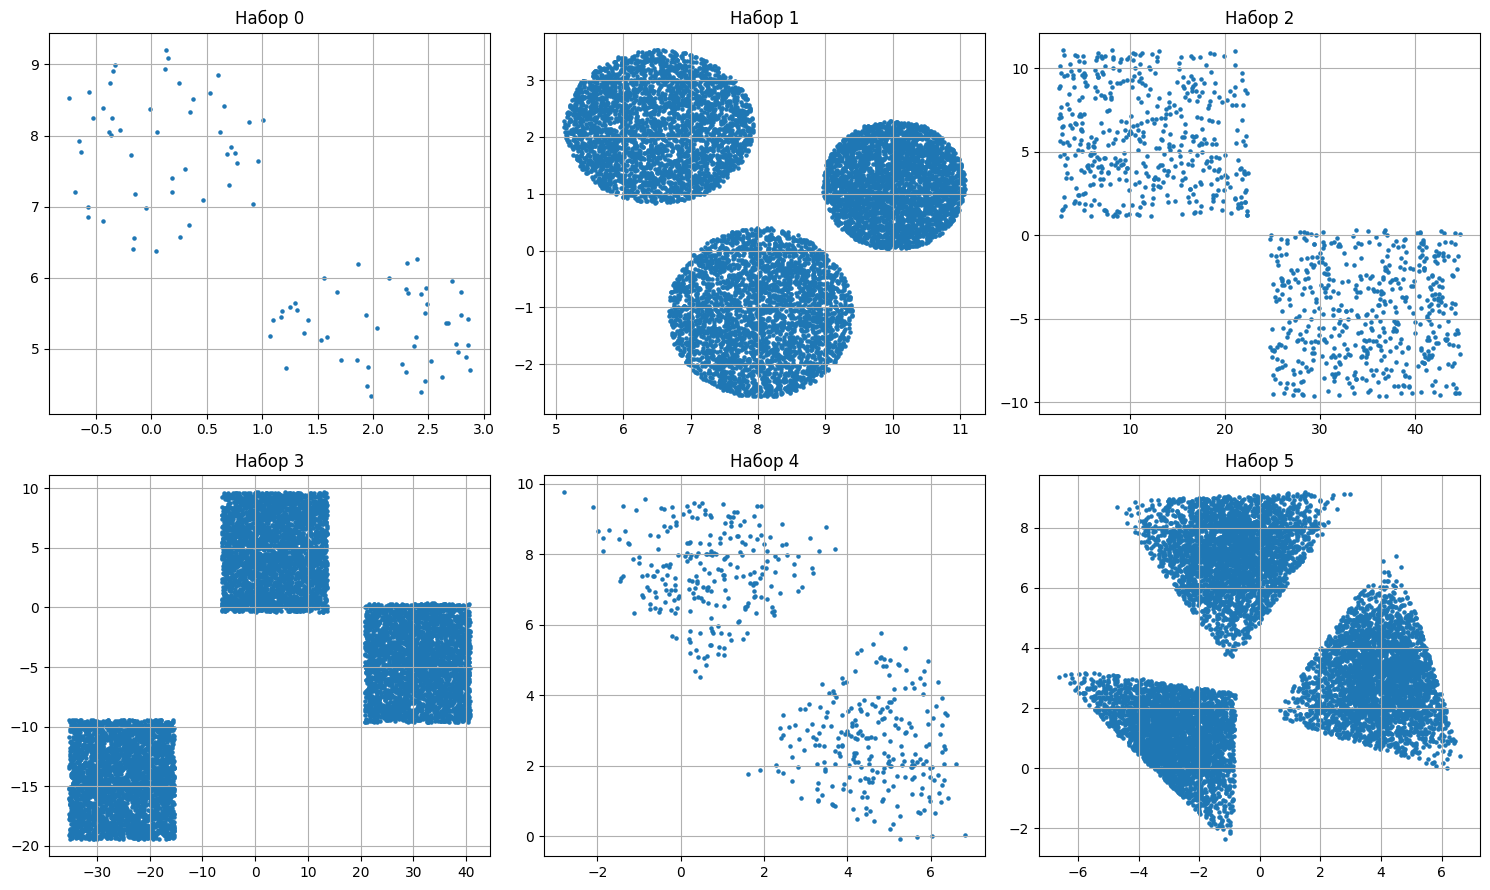

In [2]:
files = [
    "0.xls", "1.xls", "2.xlsx", "3.xlsx", "4.xlsx", "5.xlsx"
]

all_points = []
for filename in files:
    table = pd.read_excel(filename, header=None, names=["x", "y"])
    table = table.apply(pd.to_numeric, errors="coerce").dropna()
    all_points.append(table.to_numpy())

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for number, (points, ax) in enumerate(zip(all_points, axes.ravel())):
    ax.scatter(points[:, 0], points[:, 1], s=5)
    ax.set_title(f"Набор {number}")
    ax.grid(True)
plt.tight_layout()
plt.show()


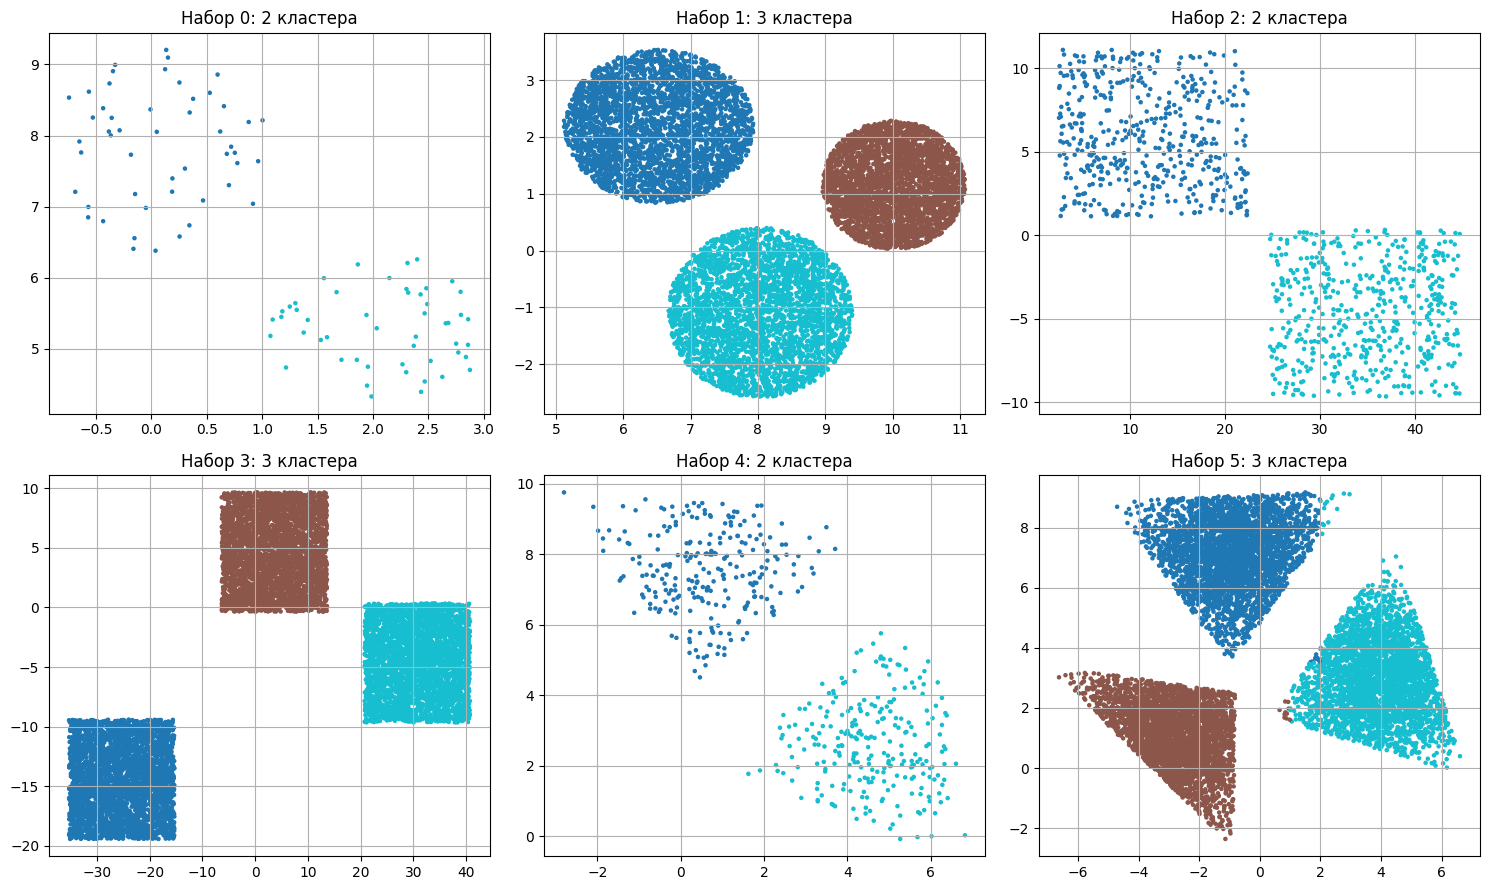

In [3]:
def manual_labels(points, number):
    x = points[:, 0]
    y = points[:, 1]

    if number == 0:
        return (x > 1.05).astype(int)
    if number == 1:
        centers = np.array([[6.5, 2.2], [10.0, 1.1], [8.0, -1.1]])
        distances = ((points[:, None] - centers) ** 2).sum(axis=2)
        return np.argmin(distances, axis=1)
    if number == 2:
        return (x > 23).astype(int)
    if number == 3:
        return np.where(x < -15, 0, np.where(x < 15, 1, 2))
    if number == 4:
        return (y < 0.75 * x + 3.0).astype(int)
    return np.where((x < 2) & (y > 3.5), 0, np.where(x < 1, 1, 2))


manual_results = []
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for number, (points, ax) in enumerate(zip(all_points, axes.ravel())):
    labels = manual_labels(points, number)
    manual_results.append(labels)
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=5)
    ax.set_title(f"Набор {number}: {len(np.unique(labels))} кластера")
    ax.grid(True)
plt.tight_layout()
plt.show()


Набор 0: средние координаты центров * 1000 = 1041, 6671
Набор 1: средние координаты центров * 1000 = 8178, 738
Набор 2: средние координаты центров * 1000 = 23130, 635


Набор 3: средние координаты центров * 1000 = 3079, -4759
Набор 4: средние координаты центров * 1000 = 2589, 4997
Набор 5: средние координаты центров * 1000 = 88, 3767


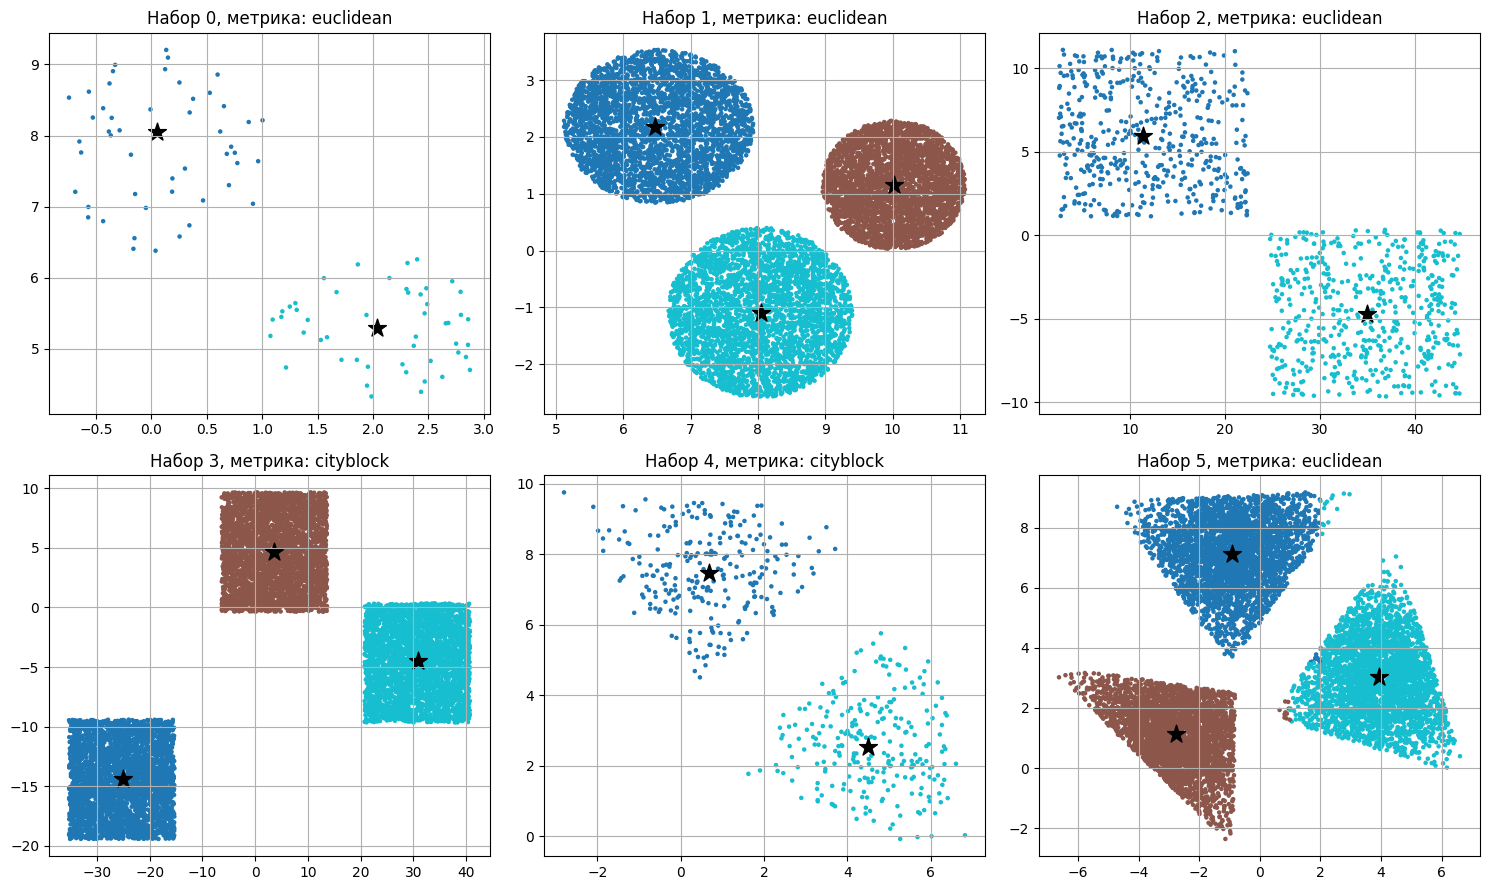

In [4]:
from scipy.spatial.distance import cdist


def find_medoid(points, metric):
    distance_sums = np.zeros(len(points))
    for start in range(0, len(points), 500):
        part = points[start:start + 500]
        distance_sums[start:start + 500] = cdist(part, points, metric=metric).sum(axis=1)
    return points[np.argmin(distance_sums)]


all_medoids = []
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for number, (points, labels, ax) in enumerate(
    zip(all_points, manual_results, axes.ravel())
):
    metric = "cityblock" if number in (3, 4) else "euclidean"
    medoids = []
    for label in np.unique(labels):
        cluster_points = points[labels == label]
        medoids.append(find_medoid(cluster_points, metric))
    medoids = np.array(medoids)
    all_medoids.append(medoids)

    answer = np.round(medoids.mean(axis=0) * 1000).astype(int)
    print(f"Набор {number}: средние координаты центров * 1000 = {answer[0]}, {answer[1]}")

    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=5)
    ax.scatter(medoids[:, 0], medoids[:, 1], c="black", marker="*", s=180)
    ax.set_title(f"Набор {number}, метрика: {metric}")
    ax.grid(True)

plt.tight_layout()
plt.show()


# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [5]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [6]:
def make_kmeans(params):
    return cluster.MiniBatchKMeans(
        n_clusters=params["n_clusters"],
        random_state=42,
        n_init=10,
    )


def make_dbscan(params):
    return cluster.DBSCAN(
        eps=params["eps"],
        min_samples=params["min_samples"],
    )


clustering_algorithms = (
    ("MiniBatch KMeans", make_kmeans),
    ("DBSCAN", make_dbscan),
)


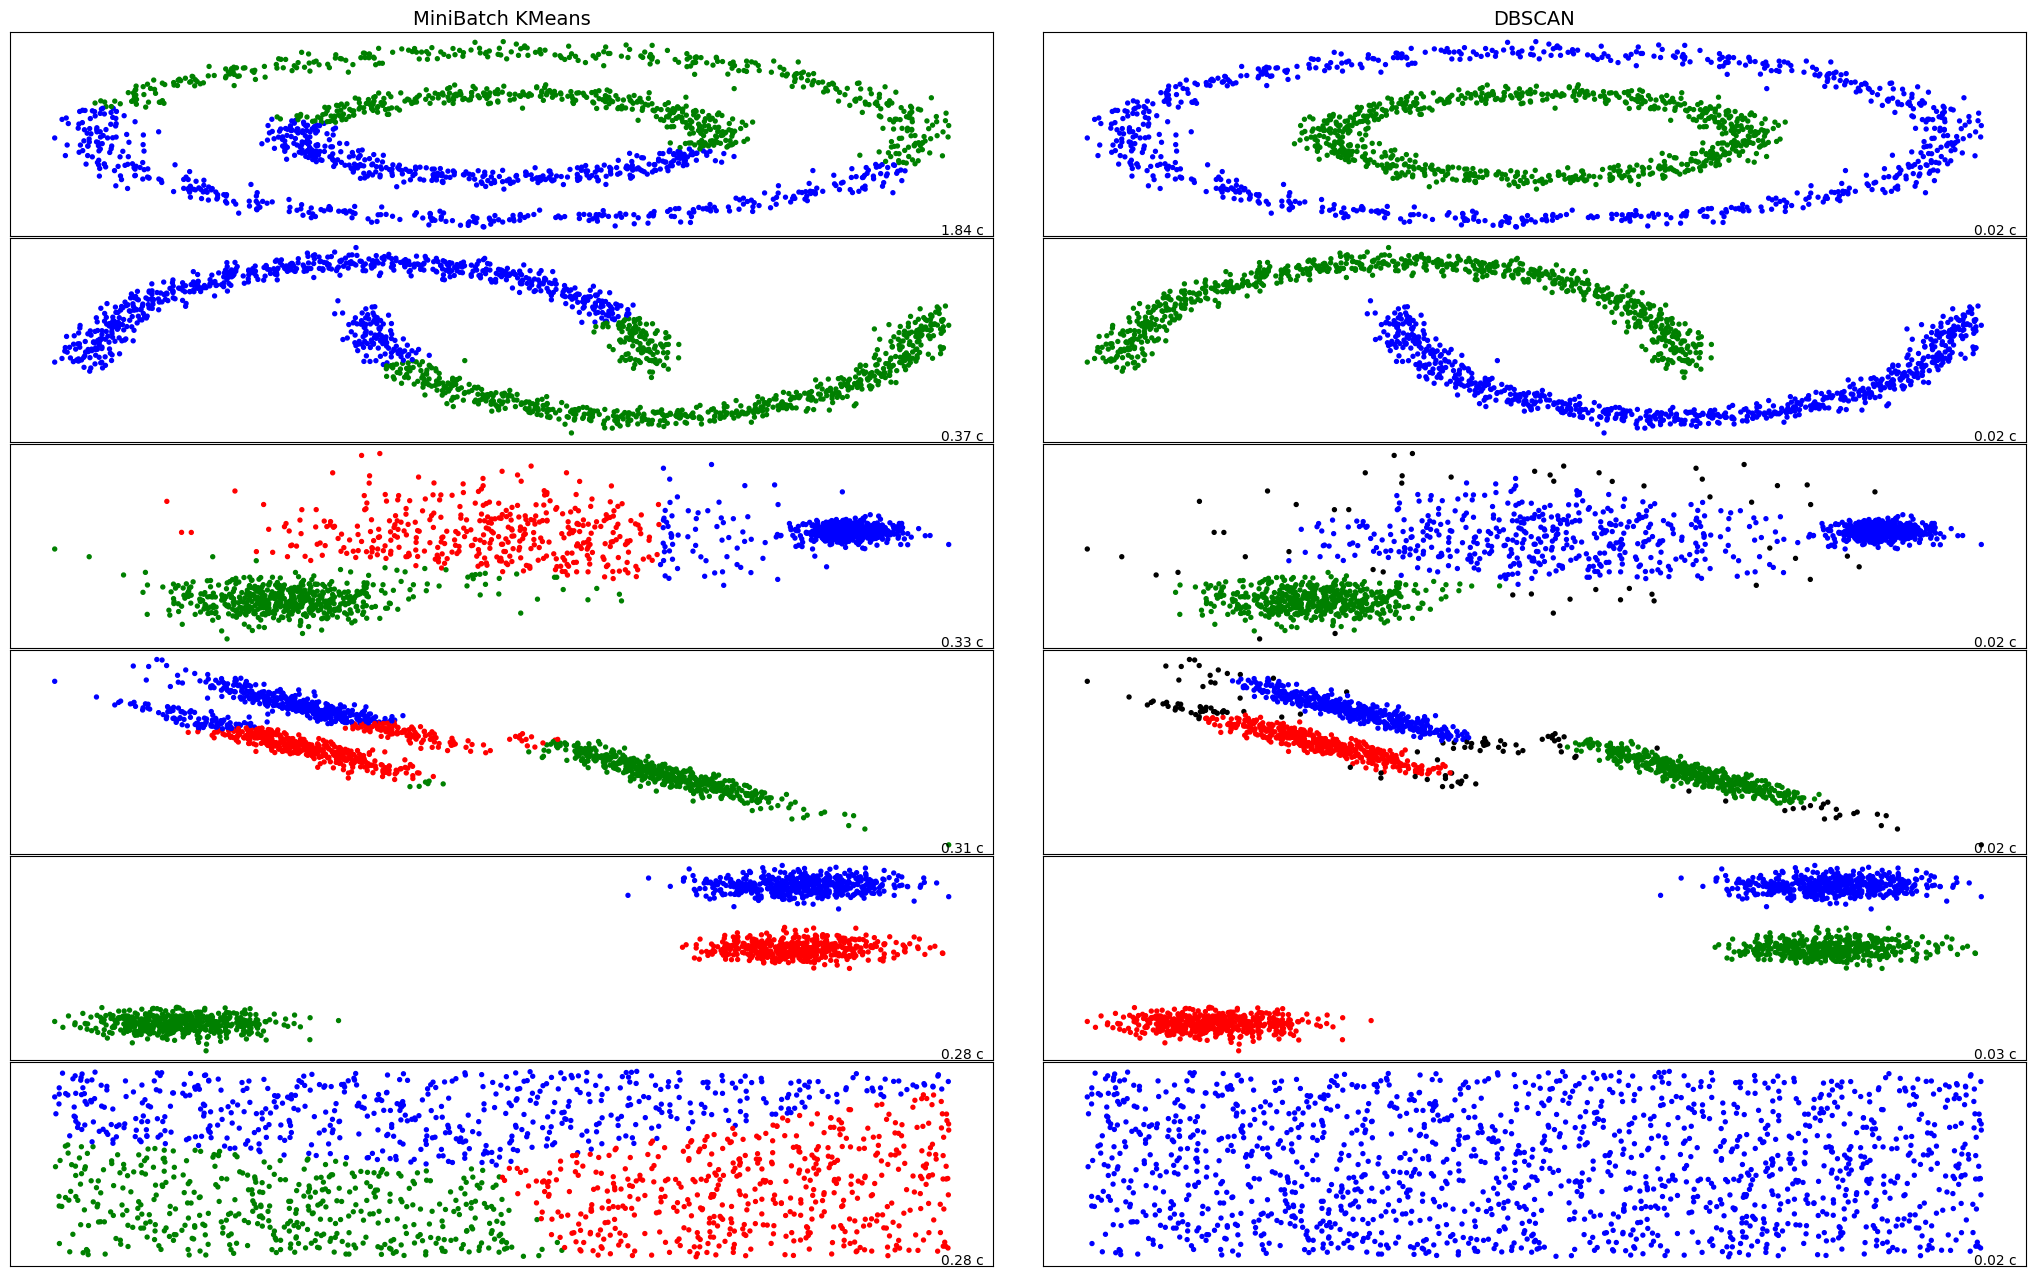

In [7]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()
        algorithm = algorithm(params)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            labels = algorithm.fit_predict(X)

        elapsed = time.time() - t0
        ax = plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            ax.set_title(name, size=14)

        colors = np.array(list(islice(cycle("bgrcmyk"), int(labels.max() + 1))))
        if -1 in labels:
            colors = np.append(colors, "black")
        ax.scatter(X[:, 0], X[:, 1], s=8, color=colors[labels])
        ax.text(
            0.99,
            0.01,
            f"{elapsed:.2f} с",
            transform=ax.transAxes,
            horizontalalignment="right",
            size=10,
        )
        ax.set_xticks(())
        ax.set_yticks(())
        plot_num += 1

plt.show()
